### Exploration for Cleaning Project 1 data

> In this notebook we're gonna explore methods for treating missing values in the dataset and class imbalanceprepare the BRFSS data before applying the regression methods from `implementations.py`.
> The raw CSV files are kept unchanged and every transformation is fitted on the training data only.

Goals :
- load the train and test files with NumPy
- inspect missing values and the target balance
- replace empty values and BRFSS non-response codes
- remove the identifier column
- impute and standardize using training statistics only
- save clean arrays that can be used by the project code

In [29]:
import numpy as np
import matplotlib.pyplot as plt

In [24]:
import os
import numpy as np

DATA_DIR = 'dataset'
X_TRAIN_PATH = os.path.join(DATA_DIR, 'x_train.csv')
Y_TRAIN_PATH = os.path.join(DATA_DIR, 'y_train.csv')
X_TEST_PATH = os.path.join(DATA_DIR, 'x_test.csv')

np.set_printoptions(suppress=True, linewidth=120)

In [25]:
x_train_raw = np.genfromtxt(
    X_TRAIN_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)
y_train_raw = np.genfromtxt(
    Y_TRAIN_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)
x_test_raw = np.genfromtxt(
    X_TEST_PATH,
    delimiter=',',
    dtype=float,
    names=True,
    missing_values='',
    filling_values=np.nan,
    autostrip=True,
)

feature_names = np.array(x_train_raw.dtype.names)
target_name = y_train_raw.dtype.names[1]

print('x_train shape:', x_train_raw.shape)
print('y_train shape:', y_train_raw.shape)
print('x_test shape:', x_test_raw.shape)
print('number of features:', len(feature_names))
print('first feature names:', feature_names[:12])

x_train shape: (328135,)
y_train shape: (328135,)
x_test shape: (109379,)
number of features: 322
first feature names: ['Id' '_STATE' 'FMONTH' 'IDATE' 'IMONTH' 'IDAY' 'IYEAR' 'DISPCODE' 'SEQNO' '_PSU' 'CTELENUM' 'PVTRESD1']


In [3]:
target_values = y_train_raw[target_name].astype(float)
unique_targets, target_counts = np.unique(target_values, return_counts=True)

print('target values:', unique_targets)
print('target counts:', target_counts)
print('positive class proportion:', np.mean(target_values == 1))

assert np.all(np.isin(unique_targets, [-1, 1]))
assert len(target_values) == len(x_train_raw)

target values: [-1.  1.]
target counts: [299160  28975]
positive class proportion: 0.08830207079403295


In [18]:
protected_columns = {
    'Id', '_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR',
    'DISPCODE', 'SEQNO', '_PSU'
}
small_missing_codes = {7.0, 9.0}
large_missing_codes = {77.0, 99.0, 777.0, 999.0, 7777.0, 9999.0, 99999.0}


def convert_raw_features(raw_data, names):
    numeric_data = np.empty((len(raw_data), len(names)), dtype=float)
    numeric_data.fill(np.nan)

    for column_index, column_name in enumerate(names):
        raw_column = raw_data[column_name].astype(str)
        missing_mask = raw_column == ''
        column = np.full(len(raw_column), np.nan, dtype=float)
        valid_mask = ~missing_mask
        column[valid_mask] = raw_column[valid_mask].astype(float)

        if column_name not in protected_columns:
            missing_mask |= np.isin(column, list(small_missing_codes))
        missing_mask |= np.isin(column, list(large_missing_codes))
        numeric_data[:, column_index] = np.where(missing_mask, np.nan, column)

    return numeric_data


x_train_with_missing = convert_raw_features(x_train_raw, feature_names)
x_test_with_missing = convert_raw_features(x_test_raw, feature_names)

missing_counts = np.sum(np.isnan(x_train_with_missing), axis=0)
print('total missing training values:', int(np.sum(missing_counts)))
print('columns with the most missing values:')
for index in np.argsort(missing_counts)[-10:][::-1]:
    print(feature_names[index], int(missing_counts[index]))

total missing training values: 49213165
columns with the most missing values:
COLGHOUS 328103
LADULT 328103
PCDMDECN 327960
ASERVIST 327907
ASDRVIST 327907
ASNOSLEP 327803
ASACTLIM 327684
ASYMPTOM 327665
ASTHMED3 327663
ASINHALR 327659


In [10]:
### exploration of features:
###### - proportion of missing values 
###### - skewness to check probably
###### - GOAL IS TO CHOOSE THE BEST TEQCHNIQUE TO FILL THEM OR JUST TROP THEM...

def feature_missingvalues(raw_data, names):
    """Function to explore missing values per feature in the dataset

    RETURN:
        values (np.array of shape (n_features, 2)):
            column 0 = nb of non-missing values of the feature
            column 1 = nb of missing values of the feature
        ratio (np.array of shape (n_features,)):
            proportion of missing values of the feature (between 0 and 1)
    """
    n_rows = len(raw_data)
    values = np.zeros((len(names), 2), dtype=int)

    for column_index, column_name in enumerate(names):
        if raw_data.dtype.names is not None:
            column = raw_data[column_name].astype(float)
        else:
            column = raw_data[:, column_index]

        nb_missing = int(np.sum(np.isnan(column)))
        values[column_index, 0] = n_rows - nb_missing
        values[column_index, 1] = nb_missing

    ratio = values[:, 1] / n_rows

    return values, ratio


In [13]:
values, ratio = feature_missingvalues(x_train_with_missing, feature_names)

order = np.argsort(ratio)[::-1]
#for index in order[:20]:
for index in order:
    print(f'{feature_names[index]:<12} non-missing={values[index, 0]:>7}  '
          f'missing={values[index, 1]:>7}  ratio={ratio[index]:.2%}')

for threshold in [0.3, 0.5, 0.7, 0.9]:
    print(f'features with > {threshold:.0%} missing:', int(np.sum(ratio > threshold)))


COLGHOUS     non-missing=     32  missing= 328103  ratio=99.99%
LADULT       non-missing=     32  missing= 328103  ratio=99.99%
PCDMDECN     non-missing=    175  missing= 327960  ratio=99.95%
ASERVIST     non-missing=    228  missing= 327907  ratio=99.93%
ASDRVIST     non-missing=    228  missing= 327907  ratio=99.93%
ASNOSLEP     non-missing=    332  missing= 327803  ratio=99.90%
ASACTLIM     non-missing=    451  missing= 327684  ratio=99.86%
ASYMPTOM     non-missing=    470  missing= 327665  ratio=99.86%
ASTHMED3     non-missing=    472  missing= 327663  ratio=99.86%
ASINHALR     non-missing=    476  missing= 327659  ratio=99.85%
ASATTACK     non-missing=    481  missing= 327654  ratio=99.85%
ASRCHKUP     non-missing=    482  missing= 327653  ratio=99.85%
STREHAB1     non-missing=    515  missing= 327620  ratio=99.84%
VINOCRE2     non-missing=    579  missing= 327556  ratio=99.82%
PCPSADE1     non-missing=    592  missing= 327543  ratio=99.82%
HAREHAB1     non-missing=    758  missin

In [26]:
features_to_drop = [
    # batch 1
    "COLGHOUS", "LADULT", "PCDMDECN", "ASERVIST", "ASDRVIST", "ASNOSLEP", "ASACTLIM", "ASYMPTOM",
    "ASTHMED3", "ASINHALR", "ASATTACK", "ASRCHKUP", "STREHAB1", "VINOCRE2", "PCPSADE1", "HAREHAB1",
    "ASTHMAGE", "CCLGHOUS", "HPVADSHT", "VIEYEXM2", "VIINSUR2", "VIMACDG2", "VIPRFVS2", "VIGLUMA2",
    "PSATIME", "PCPSARS1",
    # batch 2
    "CDHELP", "LENGEXAM", "RDUCSTRK", "RDUCHART", "RLIVPAIN", "PROFEXAM", "PCPSADI1", "PSATEST1",
    "PCPSAAD2", "PCPSARE1", "CASTHNO2", "HPLSTTST", "HPVADVC2", "CDHOUSE", "CDSOCIAL", "CDDISCUS",
    "CDASSIST", "NUMPHON2", "ASPUNSAF", "HPVTEST", "HOWLONG", "CVDASPRN", "ADPLEASR", "ADENERGY",
    "LSTBLDS3", "ARTHEXER", "ADSLEEP", "ARTHWGT", "ADEAT1", "ARTTODAY", "ARTHEDU", "ADMOVE", "ADDOWN",
    "ADTHINK", "ADFAIL", "EMTSUPRT", "LSATISFY", "ADANXEV", "MISTMNT", "LASTPAP2", "CRGVREL1",
    "CRGVPRB1", "HADHYST2", "CRGVHRS1", "HADPAP2", "HADMAM", "CRGVMST2", "CRGVLNG1", "CRGVHOUS",
    "CRGVPERS", "LONGWTCH", "SCNTLPAD", "CHKHEMO3", "SHINGLE2", "FEETCHK", "DOCTDIAB", "FEETCHK2",
    "BLDSUGAR", "EYEEXAM", "DIABEYE", "DIABEDU", "INSULIN", "SCNTPAID", "SCNTWRK1", "TETANUS",
    "SCNTLWK1", "HADSGCO1", "LASTSIG3", "LASTSMK2", "DRADVISE", "WTCHSALT", "CASTHDX2", "BLDSTOOL",
    "HADSIGM3", "DIABAGE2", "RCSGENDR", "ASTHNOW", "RCSRLTN2", "_CPRACE", "_CRACE1", "_CLLCPWT",
    "STOPSMK2", "_CHISPNC", "PREGNANT", "SCNTMNY1", "SCNTMEL1", "CRGVEXPT", "PDIABTST", "PREDIAB1",
    # batch 3
    "WHRTST10", "CAREGIV1", "HIVTSTD3", "JOINPAIN", "CIMEMLOS", "ARTHDIS2", "_PNEUMO2", "LMTJOIN3",
    "ARTHSOCL", "_FLSHOT6", "SXORIENT", "TRNSGNDR", "PAFREQ2_", "BPMEDS", "HHADULT", "SMOKDAY2",
    "IMFVPLAC", "LANDLINE", "CADULT", "CTELNUM1", "CELLFON2", "PVTRESD2", "CSTATE", "FLSHTMY2",
    "PADUR2_", "EXERHMM2", "EXEROFT2", "MAXDRNKS", "AVEDRNK2", "DRNK3GE5", "POORHLTH", "PAFREQ1_",
    "MSCODE", "CPDEMO1", "NUMHHOL2", "NUMMEN", "NUMWOMEN", "NUMADULT", "STATERES", "CTELENUM",
    "CELLFON3", "PVTRESD1", "_DUALUSE", "_DUALCOR", "PAMIN21_", "EXRACT21", "PAMIN11_", "_MINAC21",
    "METVL21_", "_HCVU651", "PAVIG21_", "_MINAC11", "ACTIN21_", "EXRACT11", "PAVIG11_", "PADUR1_",
    "EXERHMM1", "PA1MIN_", "METVL11_", "PA1VIGM_", "EXEROFT1", "ACTIN11_", "INCOME2", "_AGEG5YR",
    "PNEUVAC3", "CHOLCHK", "TOLDHI2", "STRFREQ_", "HIVTST6", "_AIDTST3", "_PAREC1", "_PASTAE1",
    "_PA30021", "_PA300R2", "_PACAT1", "_PA150R2", "_VEGLT1", "FLUSHOT6", "STRENGTH", "_PASTRNG",
    "_FRTLT1", "_RFSEAT3", "_RFSEAT2", "SEATBELT", "VEGEDA1_", "VEGETAB1", "BEANDAY_", "FVBEANS",
    "ORNGDAY_", "FVORANG", "FTJUDA1_", "FRUITJU1", "PAMISS1_", "EXERANY2", "GRENDAY_", "FVGREEN",
    "FRUTDA1_", "_BMI5CAT", "_RFBMI5", "FRUIT1", "WEIGHT2", "WTKG3", "DROCDY3_", "DRNKANY5",
    "ALCDAY5", "HTIN4", "_LMTWRK1", "_RFSMOK3", "_MRACE1", "SMOKE100", "_LMTACT1", "_LMTSCL1",
    "HTM4", "HEIGHT3", "_PRACE1", "BLOODCHO", "_RACEG21", "_RACE_G1", "_RACEGR3", "INTERNET",
    "MAXVO2_", "FC60_", "_HISPANC", "CHILDREN", "_CASTHM1", "_ASTHMS1", "_DRDXAR1", "EDUCA",
    "_LTASTH1", "_RFHYPE5", "_RFHLTH", "_DRNKWEK", "_AGE_G", "_AGE65YR", "QSTLANG", "Id", "SEQNO",
    "IDAY", "IMONTH", "IDATE", "FMONTH", "IYEAR", "DISPCODE", "QSTVER", "_VEGETEX", "_FRUITEX",
    "_VEG23", "_FRT16", "_VEGRESP", "_FRTRESP", "_MISVEGN", "_MISFRTN", "_STRWT", "_PSU", "_STSTR",
    "_LLCPWT", "_WT2RAKE", "_RAWRAKE",
]

# optional: keep survey design columns aside first
#design = x_test_with_missing[["_LLCPWT", "_STSTR", "_PSU"]].copy()

# which columns to keep
keep_mask = ~np.isin(feature_names, features_to_drop)

x_train_kept = x_train_with_missing[:, keep_mask]
x_test_kept  = x_test_with_missing[:, keep_mask]
kept_feature_names = feature_names[keep_mask]

print(x_train_kept.shape, x_test_kept.shape)
print(kept_feature_names)

(328135, 49) (109379, 49)
['_STATE' 'GENHLTH' 'PHYSHLTH' 'MENTHLTH' 'HLTHPLN1' 'PERSDOC2' 'MEDCOST' 'CHECKUP1' 'BPHIGH4' 'CVDSTRK3' 'ASTHMA3'
 'CHCSCNCR' 'CHCOCNCR' 'CHCCOPD1' 'HAVARTH3' 'ADDEPEV2' 'CHCKIDNY' 'DIABETE3' 'SEX' 'MARITAL' 'RENTHOM1' 'VETERAN3'
 'EMPLOY1' 'QLACTLM2' 'USEEQUIP' 'BLIND' 'DECIDE' 'DIFFWALK' 'DIFFDRES' 'DIFFALON' 'USENOW3' 'VIDFCLT2' 'VIREDIF3'
 'VICTRCT4' '_CHOLCHK' '_RFCHOL' '_RACE' '_AGE80' '_BMI5' '_CHLDCNT' '_EDUCAG' '_INCOMG' '_SMOKER3' '_RFBING5'
 '_RFDRHV5' '_FRUTSUM' '_VEGESUM' '_TOTINDA' '_PAINDX1']


In [27]:
def detect_categorical(X, names, max_unique=15):
    """A feature is treated as categorical if all its values are whole
    numbers and it has at most `max_unique` distinct values."""
    is_cat = np.zeros(len(names), dtype=bool)
    for j in range(X.shape[1]):
        vals = X[:, j][~np.isnan(X[:, j])]
        uniq = np.unique(vals)
        all_integers = np.all(np.mod(uniq, 1) == 0)
        is_cat[j] = all_integers and len(uniq) <= max_unique
    return is_cat

is_categorical = detect_categorical(x_train_kept, kept_feature_names)

# manual fixes where the rule is wrong
force_categorical = ["_STATE"]      # ~50 state codes, but they are labels, not quantities
force_numeric = []                  # add names here if something numeric gets flagged

is_categorical[np.isin(kept_feature_names, force_categorical)] = True
is_categorical[np.isin(kept_feature_names, force_numeric)] = False

# report
for name, cat, j in zip(kept_feature_names, is_categorical, range(len(kept_feature_names))):
    vals = x_train_kept[:, j][~np.isnan(x_train_kept[:, j])]
    print(f"{name:<10} {'CATEGORICAL' if cat else 'numeric':<12} unique={len(np.unique(vals))}")

categorical_features = kept_feature_names[is_categorical]
numeric_features = kept_feature_names[~is_categorical]
print("\nCategorical:", list(categorical_features))
print("Numeric:", list(numeric_features))

_STATE     CATEGORICAL  unique=53
GENHLTH    CATEGORICAL  unique=5
PHYSHLTH   numeric      unique=29
MENTHLTH   numeric      unique=29
HLTHPLN1   CATEGORICAL  unique=2
PERSDOC2   CATEGORICAL  unique=3
MEDCOST    CATEGORICAL  unique=2
CHECKUP1   CATEGORICAL  unique=5
BPHIGH4    CATEGORICAL  unique=4
CVDSTRK3   CATEGORICAL  unique=2
ASTHMA3    CATEGORICAL  unique=2
CHCSCNCR   CATEGORICAL  unique=2
CHCOCNCR   CATEGORICAL  unique=2
CHCCOPD1   CATEGORICAL  unique=2
HAVARTH3   CATEGORICAL  unique=2
ADDEPEV2   CATEGORICAL  unique=2
CHCKIDNY   CATEGORICAL  unique=2
DIABETE3   CATEGORICAL  unique=4
SEX        CATEGORICAL  unique=2
MARITAL    CATEGORICAL  unique=6
RENTHOM1   CATEGORICAL  unique=3
VETERAN3   CATEGORICAL  unique=2
EMPLOY1    CATEGORICAL  unique=7
QLACTLM2   CATEGORICAL  unique=2
USEEQUIP   CATEGORICAL  unique=2
BLIND      CATEGORICAL  unique=2
DECIDE     CATEGORICAL  unique=2
DIFFWALK   CATEGORICAL  unique=2
DIFFDRES   CATEGORICAL  unique=2
DIFFALON   CATEGORICAL  unique=2
USENOW3

feature     miss%   uniq    skew  suggestion
_STATE       0.00     53    0.13  symmetric -> mean
GENHLTH      0.27      5    0.37  categorical -> mode or constant
PHYSHLTH     4.04     29   -0.72  symmetric -> mean
MENTHLTH     2.96     29   -0.97  symmetric -> mean
HLTHPLN1     0.40      2    3.29  categorical -> mode or constant
PERSDOC2     0.41      3    1.62  categorical -> mode or constant
MEDCOST      0.25      2   -2.70  categorical -> mode or constant
CHECKUP1     1.35      5    2.97  categorical -> mode or constant
BPHIGH4      0.28      4   -0.34  categorical -> mode or constant
CVDSTRK3     0.22      2   -4.64  categorical -> mode or constant
ASTHMA3      0.30      2   -2.14  categorical -> mode or constant
CHCSCNCR     0.25      2   -2.76  categorical -> mode or constant
CHCOCNCR     0.20      2   -2.69  categorical -> mode or constant
CHCCOPD1     0.47      2   -3.09  categorical -> mode or constant
HAVARTH3     0.57      2   -0.70  categorical -> mode or constant
ADDEPEV

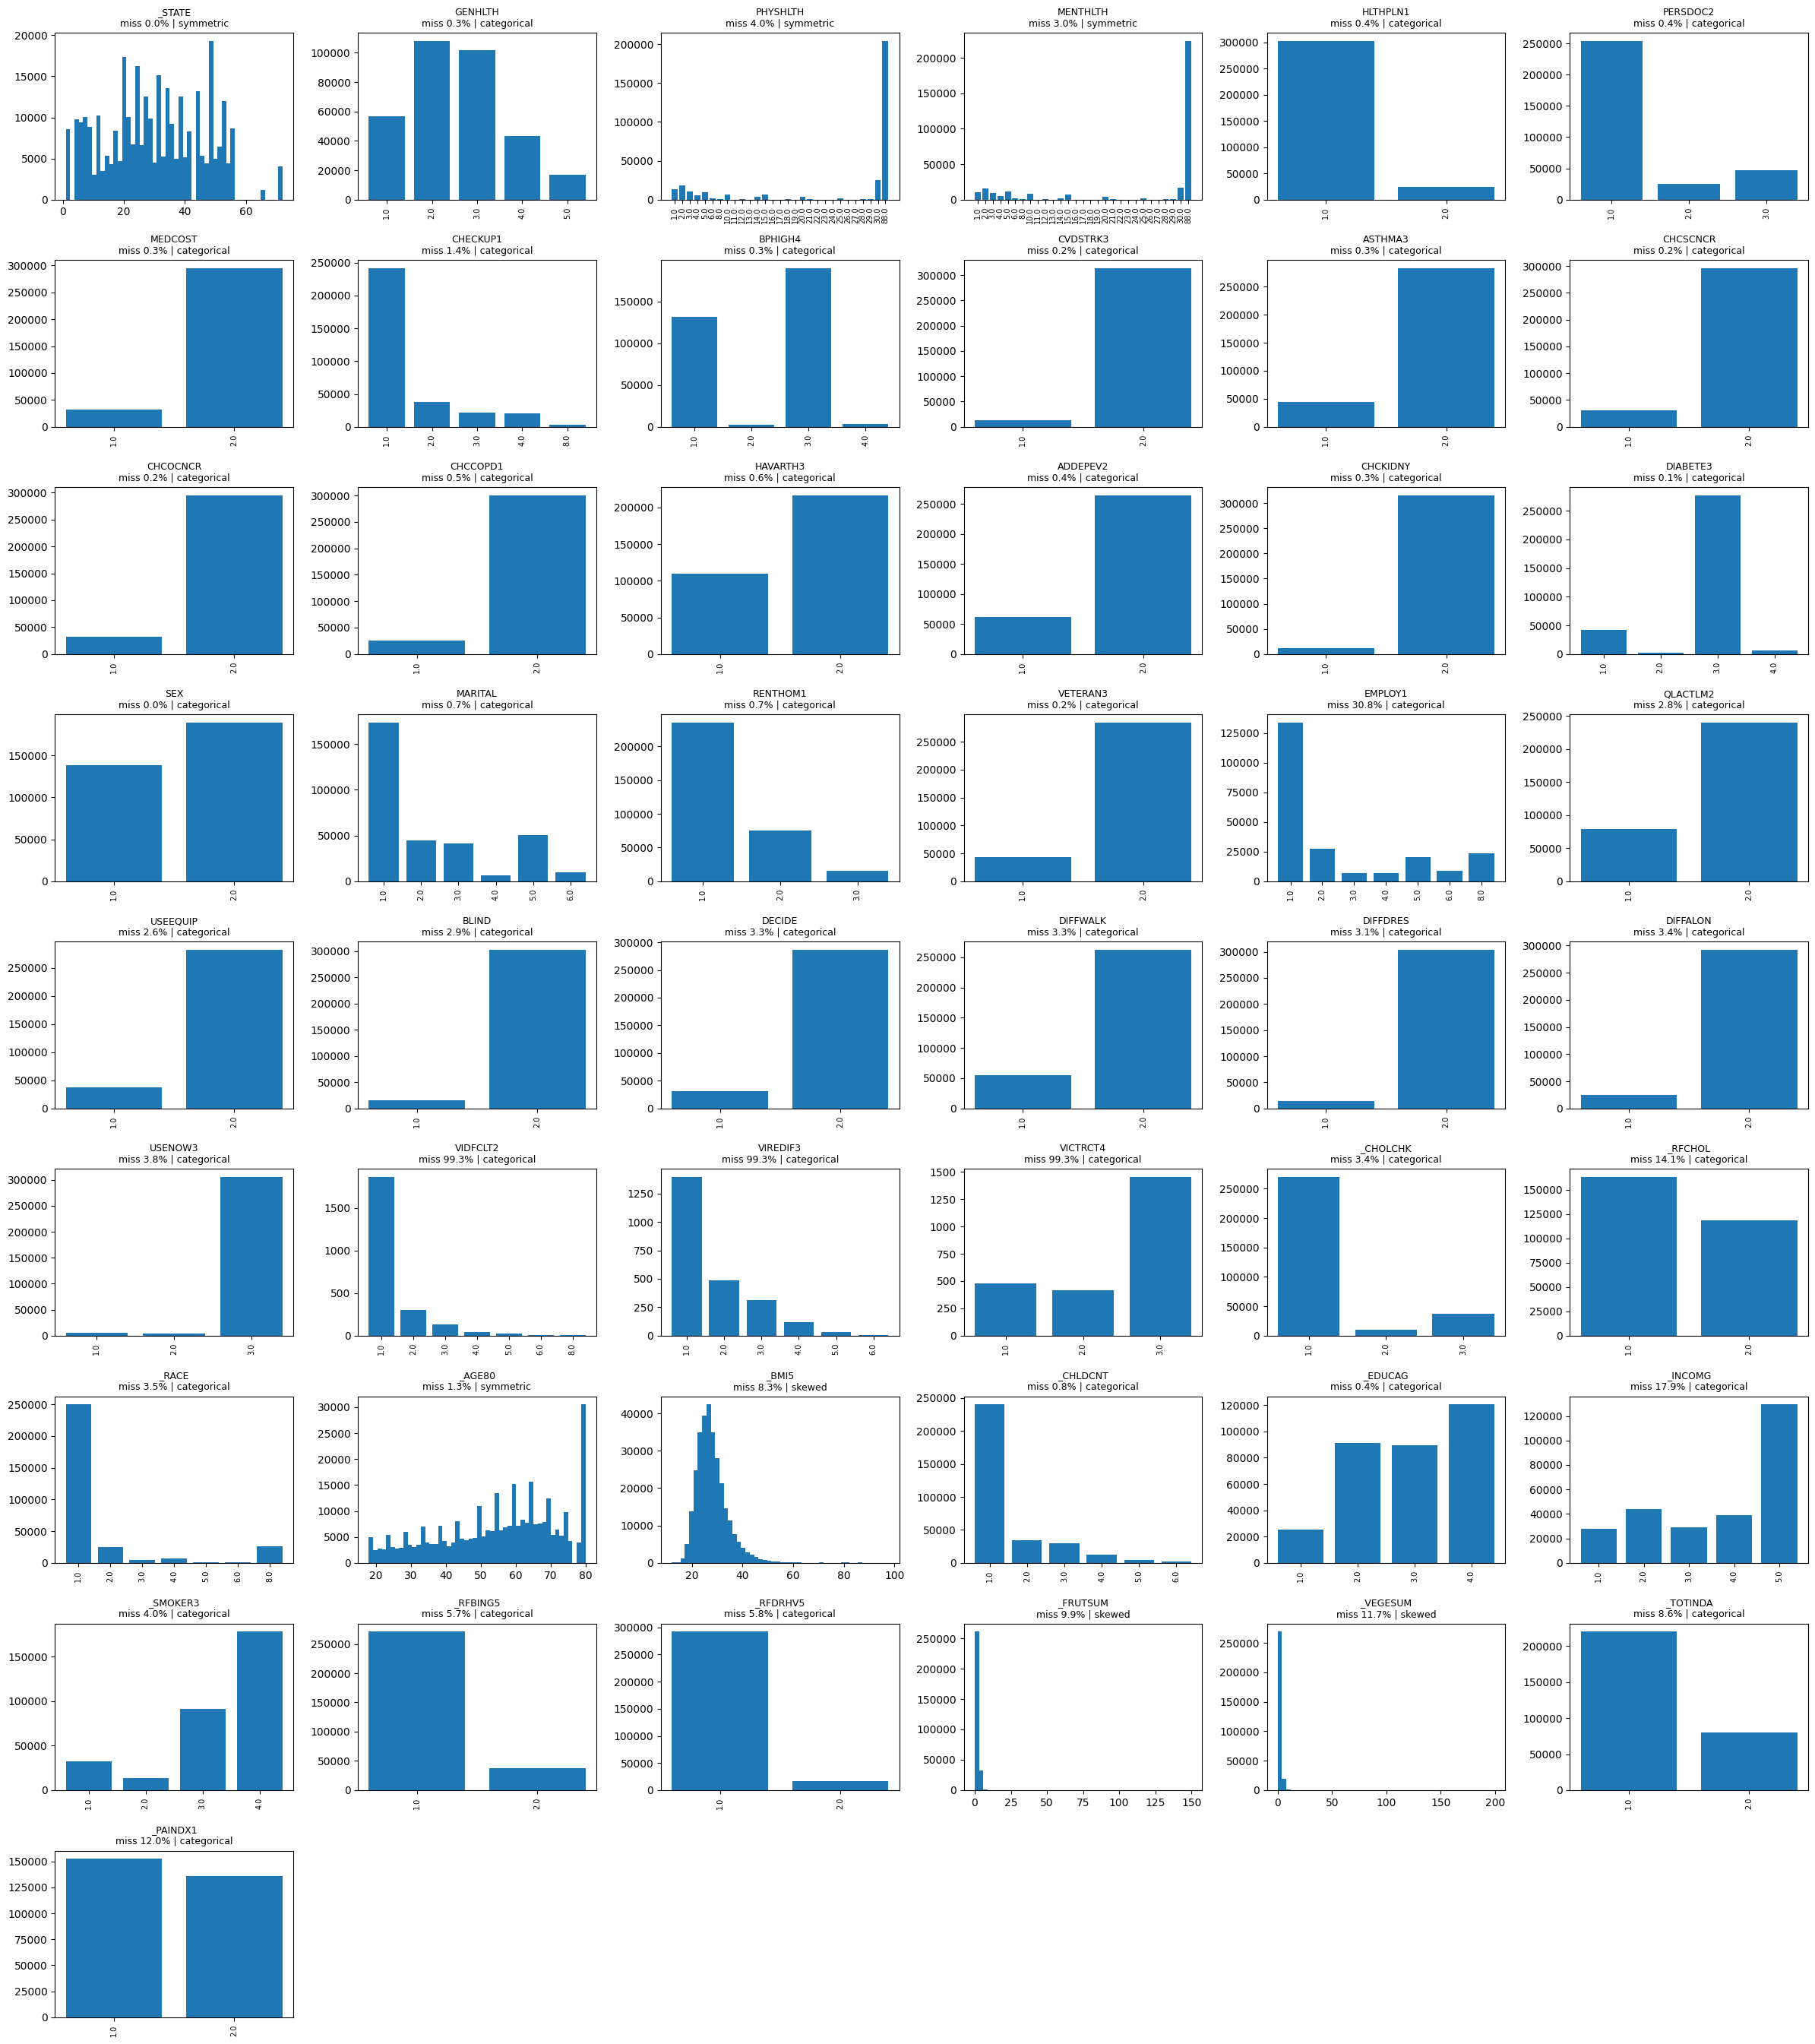

In [30]:
X = x_train_kept          # use TRAIN only to decide imputation
names = kept_feature_names

def skewness(v):
    s = v.std()
    return 0.0 if s == 0 else np.mean((v - v.mean()) ** 3) / s ** 3

summary = []
for j, name in enumerate(names):
    col = X[:, j]
    vals = col[~np.isnan(col)]
    miss = np.isnan(col).mean() * 100
    n_unique = len(np.unique(vals))
    sk = skewness(vals) if len(vals) else np.nan

    if n_unique <= 10:
        suggestion = "categorical -> mode or constant"
    elif abs(sk) > 1:
        suggestion = "skewed -> median"
    else:
        suggestion = "symmetric -> mean"
    summary.append((name, miss, n_unique, sk, suggestion))

# ---- printed table ----
print(f"{'feature':<10} {'miss%':>6} {'uniq':>6} {'skew':>7}  suggestion")
for name, miss, nu, sk, sug in summary:
    print(f"{name:<10} {miss:6.2f} {nu:6d} {sk:7.2f}  {sug}")

# ---- histograms ----
n_cols = 6
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = axes.ravel()

for j, (name, miss, nu, sk, sug) in enumerate(summary):
    vals = X[:, j][~np.isnan(X[:, j])]
    ax = axes[j]
    if nu <= 30:   # discrete: one bar per value
        u, c = np.unique(vals, return_counts=True)
        ax.bar(u.astype(str), c)
        ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    else:
        ax.hist(vals, bins=50)
    ax.set_title(f"{name}\nmiss {miss:.1f}% | {sug.split(' ->')[0]}", fontsize=9)

for ax in axes[len(names):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Dealing with categorical data:

In [33]:

#####this is for mode version

def column_mode(col):
    vals = col[~np.isnan(col)]
    uniq, counts = np.unique(vals, return_counts=True)
    return uniq[np.argmax(counts)]

cat_idx = np.where(is_categorical)[0]

# compute modes on TRAIN only
modes = {j: column_mode(x_train_kept[:, j]) for j in cat_idx}

x_train_filled = x_train_kept.copy()
x_test_filled = x_test_kept.copy()

for j in cat_idx:
    x_train_filled[np.isnan(x_train_filled[:, j]), j] = modes[j]
    x_test_filled[np.isnan(x_test_filled[:, j]), j] = modes[j]

for j in cat_idx:
    print(f"{kept_feature_names[j]:<10} mode = {modes[j]}")

#### this is for constant...

for j in cat_idx:
    x_train_filled[np.isnan(x_train_filled[:, j]), j] = -1
    x_test_filled[np.isnan(x_test_filled[:, j]), j] = -1

_STATE     mode = 20.0
GENHLTH    mode = 2.0
HLTHPLN1   mode = 1.0
PERSDOC2   mode = 1.0
MEDCOST    mode = 2.0
CHECKUP1   mode = 1.0
BPHIGH4    mode = 3.0
CVDSTRK3   mode = 2.0
ASTHMA3    mode = 2.0
CHCSCNCR   mode = 2.0
CHCOCNCR   mode = 2.0
CHCCOPD1   mode = 2.0
HAVARTH3   mode = 2.0
ADDEPEV2   mode = 2.0
CHCKIDNY   mode = 2.0
DIABETE3   mode = 3.0
SEX        mode = 2.0
MARITAL    mode = 1.0
RENTHOM1   mode = 1.0
VETERAN3   mode = 2.0
EMPLOY1    mode = 1.0
QLACTLM2   mode = 2.0
USEEQUIP   mode = 2.0
BLIND      mode = 2.0
DECIDE     mode = 2.0
DIFFWALK   mode = 2.0
DIFFDRES   mode = 2.0
DIFFALON   mode = 2.0
USENOW3    mode = 3.0
VIDFCLT2   mode = 1.0
VIREDIF3   mode = 1.0
VICTRCT4   mode = 3.0
_CHOLCHK   mode = 1.0
_RFCHOL    mode = 1.0
_RACE      mode = 1.0
_CHLDCNT   mode = 1.0
_EDUCAG    mode = 4.0
_INCOMG    mode = 5.0
_SMOKER3   mode = 4.0
_RFBING5   mode = 1.0
_RFDRHV5   mode = 1.0
_TOTINDA   mode = 1.0
_PAINDX1   mode = 1.0


### Dealing with numerical data:

In [ ]:
num_idx = np.where(~is_categorical)[0]

x_train_filled = x_train_filled.copy()
x_test_filled = x_test_filled.copy()

# --- 1. special codes (edit per codebook) ---
special_codes = {
    "PHYSHLTH": {"to_zero": [88], "to_nan": [77, 99]},
    "MENTHLTH": {"to_zero": [88], "to_nan": [77, 99]},
}
for name, rules in special_codes.items():
    j = np.where(kept_feature_names == name)[0]
    if len(j) == 0:
        continue
    j = j[0]
    for X in (x_train_filled, x_test_filled):
        X[np.isin(X[:, j], rules["to_zero"]), j] = 0
        X[np.isin(X[:, j], rules["to_nan"]), j] = np.nan

# --- 2. median imputation (+ optional missing indicator) ---
medians = {j: np.nanmedian(x_train_filled[:, j]) for j in num_idx}
missing_flags_train, missing_flags_test, flag_names = [], [], []

for j in num_idx:
    miss_rate = np.isnan(x_train_filled[:, j]).mean()
    if miss_rate > 0.05:   # add indicator only when missingness is substantial
        missing_flags_train.append(np.isnan(x_train_filled[:, j]).astype(float))
        missing_flags_test.append(np.isnan(x_test_filled[:, j]).astype(float))
        flag_names.append(kept_feature_names[j] + "_missing")
    x_train_filled[np.isnan(x_train_filled[:, j]), j] = medians[j]
    x_test_filled[np.isnan(x_test_filled[:, j]), j] = medians[j]

# --- 3. clip outliers at 1st / 99th percentile ---
for j in num_idx:
    lo, hi = np.percentile(x_train_filled[:, j], [1, 99])
    x_train_filled[:, j] = np.clip(x_train_filled[:, j], lo, hi)
    x_test_filled[:, j] = np.clip(x_test_filled[:, j], lo, hi)

# --- 4. standardize ---
mu = x_train_filled[:, num_idx].mean(axis=0)
sigma = x_train_filled[:, num_idx].std(axis=0)
sigma[sigma == 0] = 1   # avoid dividing by zero for constant columns
x_train_filled[:, num_idx] = (x_train_filled[:, num_idx] - mu) / sigma
x_test_filled[:, num_idx] = (x_test_filled[:, num_idx] - mu) / sigma

# add missing-indicator columns at the end
if flag_names:
    x_train_filled = np.column_stack([x_train_filled] + missing_flags_train)
    x_test_filled = np.column_stack([x_test_filled] + missing_flags_test)
    final_feature_names = np.concatenate([kept_feature_names, flag_names])
else:
    final_feature_names = kept_feature_names

print(x_train_filled.shape, x_test_filled.shape)
print("NaNs left:", np.isnan(x_train_filled[:, num_idx]).sum(), np.isnan(x_test_filled[:, num_idx]).sum())

### CLASS IMBALANCE

Target: _MICHD   total samples: 328135
  class   -1:  299160  (91.17%)
  class    1:   28975  ( 8.83%)
Imbalance ratio (majority / minority): 10.3 : 1


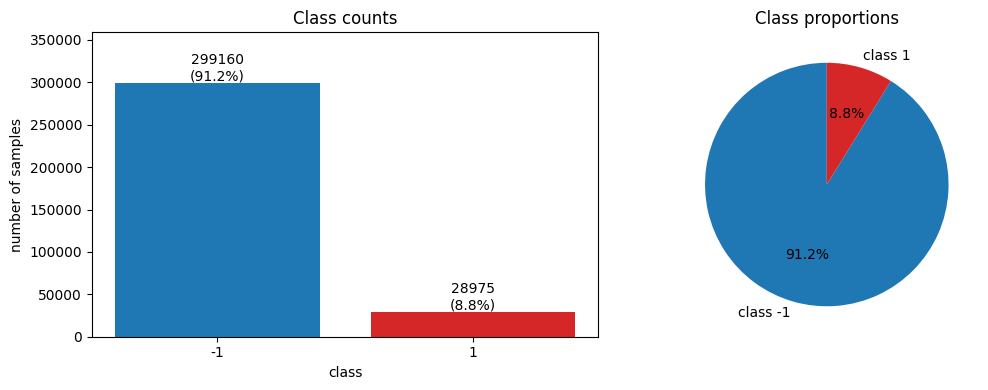

In [34]:


y = y_train_raw[target_name]
y = y[~np.isnan(y)]

classes, counts = np.unique(y, return_counts=True)
percent = counts / counts.sum() * 100

print(f"Target: {target_name}   total samples: {counts.sum()}")
for c, n, p in zip(classes, counts, percent):
    print(f"  class {c:>4g}: {n:>7d}  ({p:5.2f}%)")
print(f"Imbalance ratio (majority / minority): {counts.max() / counts.min():.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# bar chart with counts and percentages
bars = axes[0].bar([str(int(c)) for c in classes], counts, color=["tab:blue", "tab:red"][:len(classes)])
for b, n, p in zip(bars, counts, percent):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height(), f"{n}\n({p:.1f}%)",
                 ha="center", va="bottom", fontsize=10)
axes[0].set_title("Class counts")
axes[0].set_xlabel("class")
axes[0].set_ylabel("number of samples")
axes[0].set_ylim(0, counts.max() * 1.2)

# pie chart
axes[1].pie(counts, labels=[f"class {int(c)}" for c in classes], autopct="%1.1f%%",
            colors=["tab:blue", "tab:red"][:len(classes)], startangle=90)
axes[1].set_title("Class proportions")

plt.tight_layout()
plt.show()

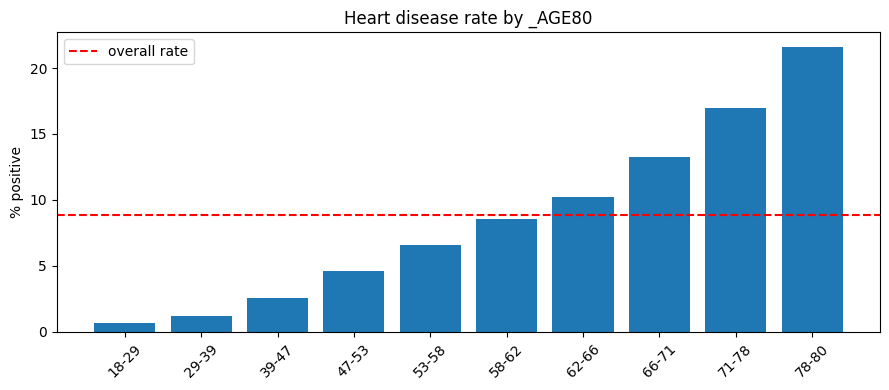

In [35]:
feature = "_AGE80"   # try also "SEX", "GENHLTH", "_SMOKER3", "DIABETE3"
j = np.where(feature_names == feature)[0][0]
x = x_train_raw[feature]            # raw (unscaled) values are easier to read
y_all = y_train_raw[target_name]
positive = classes.max()            # assumes the larger label (1) means heart disease

mask = ~np.isnan(x) & ~np.isnan(y_all)
x, y_all = x[mask], y_all[mask]

if len(np.unique(x)) > 15:          # bin numeric features into 10 groups
    edges = np.percentile(x, np.linspace(0, 100, 11))
    groups = np.digitize(x, edges[1:-1])
    labels = [f"{edges[i]:.0f}-{edges[i+1]:.0f}" for i in range(10)]
else:
    groups = x
    labels = [str(int(v)) for v in np.unique(x)]

rates = [np.mean(y_all[groups == g] == positive) * 100 for g in np.unique(groups)]

plt.figure(figsize=(9, 4))
plt.bar(labels[:len(rates)], rates)
plt.axhline(np.mean(y_all == positive) * 100, color="red", linestyle="--", label="overall rate")
plt.title(f"Heart disease rate by {feature}")
plt.ylabel("% positive")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
##### HOW TO DEAL WITH CLASS IMBALANCE? SMOTE?... apply after treatemnt of missing values?

In [ ]:
# to build these function we can use only numpy..

def random_undersampling():
    return ...

def random_oversampling():
    return ...

def SMOTE():
    return ...

def ADASYN():
    return ...

def TomekLink():
    return ...


IndentationError: expected an indented block (355985588.py, line 12)

In [ ]:
def _knn(query, data, k, exclude_self=False):
    """Indices of the k nearest neighbours (Euclidean) in `data` for each row of `query`.
    Computed in batches so memory stays manageable with ~300k rows."""
    kk = k + 1 if exclude_self else k
    data_sq = np.sum(data ** 2, axis=1)
    batch = max(1, int(2e7 // data.shape[0]))          # ~160 MB distance block
    out = np.empty((query.shape[0], kk), dtype=np.int64)
    for s in range(0, query.shape[0], batch):
        q = query[s:s + batch]
        d = np.sum(q ** 2, axis=1)[:, None] + data_sq[None, :] - 2 * q @ data.T
        idx = np.argpartition(d, kk - 1, axis=1)[:, :kk]
        rows = np.arange(idx.shape[0])[:, None]
        order = np.argsort(d[rows, idx], axis=1)
        out[s:s + batch] = idx[rows, order]
    return out[:, 1:] if exclude_self else out     # drop the point itself


def _shuffle(X, y, rng):
    p = rng.permutation(len(y))
    return X[p], y[p]


def random_undersampling(X, y, ratio=1.0, seed=42):
    """Keep all minority samples; randomly keep ratio * n_minority majority samples."""
    rng = np.random.default_rng(seed)
    min_idx, maj_idx = np.where(y == 1)[0], np.where(y == 0)[0]
    n_keep = min(len(maj_idx), int(len(min_idx) * ratio))
    keep = np.concatenate([min_idx, rng.choice(maj_idx, n_keep, replace=False)])
    return _shuffle(X[keep], y[keep], rng)


def random_oversampling(X, y, ratio=1.0, seed=42):
    """Duplicate random minority samples until n_minority = ratio * n_majority."""
    rng = np.random.default_rng(seed)
    min_idx, maj_idx = np.where(y == 1)[0], np.where(y == 0)[0]
    n_new = max(0, int(len(maj_idx) * ratio) - len(min_idx))
    extra = rng.choice(min_idx, n_new, replace=True)
    keep = np.concatenate([np.arange(len(y)), extra])
    return _shuffle(X[keep], y[keep], rng)


def SMOTE(X, y, k=5, ratio=1.0, seed=42):
    """Create synthetic minority points on the line between a minority sample
    and one of its k nearest minority neighbours."""
    rng = np.random.default_rng(seed)
    X_min = X[y == 1]
    n_new = max(0, int(np.sum(y == 0) * ratio) - len(X_min))
    nn = _knn(X_min, X_min, k, exclude_self=True)

    base = rng.integers(0, len(X_min), n_new)
    nbr = nn[base, rng.integers(0, k, n_new)]
    gap = rng.random((n_new, 1))
    X_new = X_min[base] + gap * (X_min[nbr] - X_min[base])

    X_out = np.vstack([X, X_new])
    y_out = np.concatenate([y, np.ones(n_new, dtype=y.dtype)])
    return _shuffle(X_out, y_out, rng)


def ADASYN(X, y, k=5, ratio=1.0, seed=42):
    """Like SMOTE, but generates more synthetic points around minority samples
    that are surrounded by many majority samples (the 'hard' ones)."""
    rng = np.random.default_rng(seed)
    min_idx = np.where(y == 1)[0]
    X_min = X[min_idx]
    G = max(0, int(np.sum(y == 0) * ratio) - len(min_idx))

    # difficulty: fraction of majority points among k neighbours in the full data
    nn_all = _knn(X_min, X, k, exclude_self=True)
    r = np.mean(y[nn_all] == 0, axis=1)
    r = r / r.sum() if r.sum() > 0 else np.full(len(r), 1 / len(r))
    g = np.round(r * G).astype(int)                 # samples to create per point

    nn_min = _knn(X_min, X_min, k, exclude_self=True)
    base = np.repeat(np.arange(len(X_min)), g)
    nbr = nn_min[base, rng.integers(0, k, len(base))]
    gap = rng.random((len(base), 1))
    X_new = X_min[base] + gap * (X_min[nbr] - X_min[base])

    X_out = np.vstack([X, X_new])
    y_out = np.concatenate([y, np.ones(len(base), dtype=y.dtype)])
    return _shuffle(X_out, y_out, rng)


def TomekLink(X, y, seed=42):
    """Remove majority samples that form a Tomek link with a minority sample
    (two points of opposite class that are each other's nearest neighbour)."""
    rng = np.random.default_rng(seed)
    min_idx = np.where(y == 1)[0]

    nn_of_min = _knn(X[min_idx], X, 1, exclude_self=True)[:, 0]
    cand = nn_of_min[y[nn_of_min] == 0]            # majority points closest to a minority point
    cand_min = min_idx[y[nn_of_min] == 0]

    nn_of_cand = _knn(X[cand], X, 1, exclude_self=True)[:, 0]
    to_remove = np.unique(cand[nn_of_cand == cand_min])   # mutual nearest neighbours

    keep = np.setdiff1d(np.arange(len(y)), to_remove)
    print(f"TomekLink: removed {len(to_remove)} majority samples")
    return _shuffle(X[keep], y[keep], rng)